In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os.path
import os
import jinja2

plt.rcParams.update({"font.size": 16, "figure.figsize": [10.0, 8]})


def generate_from_template(templatefile, outfile, **kwargs):
    with open(templatefile, "r") as infile, open(outfile, "w") as outfile:
        output = jinja2.Template(infile.read()).render(kwargs)
        outfile.write(output)


try:
    workdir
except NameError:
    workdir = %pwd
else:
    %cd -q $workdir
%cd -q $workdir/

faunus_exe = "$HOME/github/faunus-rs/target/release/faunus"  # change this!!

## Generate Faunus input file from a _template_

In the following snippet, we start from a template input file, `template.yml` and generate a final input file for Faunus. The idea is that the template contains named variables that we can fill in and save an input file.

In [2]:
%cd -q $workdir
# generate_from_template('template-rs.yaml', 'isotropic/input.yml', micro_steps=100, structure='../P00.xyz')
# generate_from_template('template-rs.yaml', 'dipolar/input.yml', micro_steps=100, structure='../P18.xyz')

## Run Monte Carlo simulation

We now parse the input to the _faunus_ executable which we assume you have compiled elsewhere.

In [3]:
#%cd -q $workdir/isotropic # isotropic, dipolar, bulk
#!{faunus_exe} run -i input.yml -s state.yaml

## Extract information from the main output file: `output.yaml`

The faunus-rs `output.yaml` file contains structured analysis results, including
`!CollectiveVariable property: Molarity` blocks (one per atomtype) and a
`!VirtualVolumeMove` block with the excess pressure. We parse the YAML with
custom-tags ignored, then look up sections by name.

In [4]:
import yaml


# YAML loader that ignores faunus-rs custom tags like `!Cuboid`, `!Fixed`, etc.
class _Loader(yaml.SafeLoader):
    pass


def _ignore_tag(loader, _tag, node):
    if isinstance(node, yaml.ScalarNode):
        return loader.construct_scalar(node)
    if isinstance(node, yaml.SequenceNode):
        return loader.construct_sequence(node)
    return loader.construct_mapping(node)


_Loader.add_multi_constructor("!", _ignore_tag)


def loadOutput(path):
    """Load a faunus-rs output.yaml as a plain dict."""
    with open(path) as f:
        return yaml.load(f, Loader=_Loader)


def findAnalysis(j, kind, **filters):
    """Find an analysis entry by tag with optional field filters.
    Example: findAnalysis(j, 'collectivevariable', property='Molarity',
                          description='selection: atomtype Na')."""
    for entry in j.get("analysis", []):
        if kind not in entry:
            continue
        value = entry[kind]
        if all(value.get(k) == v for k, v in filters.items()):
            return value
    return None


def molarity(j, atomtype):
    """Mean molarity (M) of a given atom type, from CollectiveVariable analysis."""
    cv = findAnalysis(
        j,
        "collectivevariable",
        property="Molarity",
        description=f"selection: atomtype {atomtype}",
    )
    return cv["mean"] if cv else 0.0


%cd -q $workdir/dipolar
j = loadOutput("output.yaml")
print(f"Na+ concentration (M) = {molarity(j, 'Na'):.4g}")
print(f"Cl- concentration (M) = {molarity(j, 'Cl'):.4g}")
print(f"ionic strength (M)    = {0.5 * (molarity(j, 'Na') + molarity(j, 'Cl')):.4g}")

Na+ concentration (M) = 0.1618
Cl- concentration (M) = 0.04292
ionic strength (M)    = 0.1024


In [5]:
def excessPressure(j):
    """Excess pressure (mM) from the !VirtualVolumeMove analysis."""
    return findAnalysis(j, "virtualvolumemove")["Pex/mM"]


def macroionMolarity(j):
    """Macroion number density (M) from blocks + cell."""
    n_macroions = 0
    for block in j.get("blocks", []):
        if block["molecule"] == "macroion":
            n_macroions = block.get("active") or block["N"]
            break
    cell = j["cell"]
    Lx, Ly, Lz = (
        (cell[0], cell[1], cell[2]) if isinstance(cell, list) else (cell, cell, cell)
    )
    return n_macroions / (Lx * Ly * Lz) * 1e27 / 6.022e23  # → M


def pressureBreakdown(outfile):
    """Per-species ideal pressure (mM) plus excess from virtual-volume."""
    j = loadOutput(outfile)
    p_na = molarity(j, "Na") * 1000
    p_cl = molarity(j, "Cl") * 1000
    p_macroion = macroionMolarity(j) * 1000
    p_ex = excessPressure(j)
    return dict(
        Na=p_na,
        Cl=p_cl,
        macroion=p_macroion,
        excess=p_ex,
        total=p_na + p_cl + p_macroion + p_ex,
    )


%cd -q $workdir

files = dict(
    Bulk="bulk/output.yaml",
    Neutral="neutral/output.yaml",
    Isotropic="isotropic/output.yaml",
    Anisotropic="dipolar/output.yaml",
)
d = pd.DataFrame(
    {name: pressureBreakdown(f) for name, f in files.items() if os.path.exists(f)}
).T
if "Bulk" in d.index:
    d = (d - d.loc["Bulk"]).drop("Bulk")  # Δ-pressures relative to bulk
pd.set_option("display.precision", 1)
d

,Na,Cl,macroion,excess,total
Isotropic,26.8,-92.2,14.9,193.5,143.0
Anisotropic,33.8,-85.2,14.9,128.0,91.4


In [6]:
%cd -q $workdir/bulk

# Bulk diagnostics: equilibrium NaCl concentration vs. the prescribed activity,
# and a sanity-check against the excess-pressure (virtual-volume) analysis.

bulk = loadOutput("output.yaml")
with open("input.yml") as f:
    bulk_input = yaml.load(f, Loader=_Loader)


def molecule_activity(yaml_doc, name):
    """Read a molecule's `activity` (M) from a parsed input YAML."""
    for mol in yaml_doc.get("molecules", []):
        if mol.get("name") == name:
            return mol.get("activity")
    return None


def atom_sigma(yaml_doc, name):
    """Read an atom's `sigma` (Å) from a parsed input YAML."""
    for atom in yaml_doc.get("atoms", []):
        if atom.get("name") == name:
            return atom.get("sigma")
    return None


def ionicStrength(j):
    """Half-sum of microion concentrations for a 1:1 electrolyte (M)."""
    return 0.5 * (molarity(j, "Na") + molarity(j, "Cl"))


a = molecule_activity(bulk_input, "Cations")  # both species share activity
c_na, c_cl = molarity(bulk, "Na"), molarity(bulk, "Cl")
ionic = ionicStrength(bulk)
size = 0.5 * (
    atom_sigma(bulk_input, "Na") + atom_sigma(bulk_input, "Cl")
)  # closest-approach (Å)

# Activity coefficients γ = a / c.
gamma_pm = ((a / c_na) * (a / c_cl)) ** 0.5

# Osmotic coefficient from virtual-volume excess pressure:
# P_total = ϕ · P_ideal, with P_ideal = (c_+ + c_-)·RT in matching units (mM).
P_ex = excessPressure(bulk)
P_ideal = (c_na + c_cl) * 1000  # M → mM
phi = 1 + P_ex / P_ideal

# Bjerrum length and inverse Debye length from medium + ionic strength.
T = bulk["medium"]["temperature"]
eps_r = (
    78.36
    if bulk["medium"]["permittivity"] == "Water"
    else float(bulk["medium"]["permittivity"])
)
lambda_B = 1.671e5 / (eps_r * T)  # Å
kappa = (8 * np.pi * lambda_B * ionic * 6.022e-4) ** 0.5  # Å⁻¹

# Limiting-law:           ln γ± = -κ λ_B / 2
# Size-corrected DH:      ln γ± = -κ λ_B / [2 (1 + κ a)]   (Robinson–Stokes)
ln_gamma_LL = -kappa * lambda_B / 2
ln_gamma_DH_a = -kappa * lambda_B / (2 * (1 + kappa * size))

print(f"prescribed activity   = {a} M")
print(f"final [Na+] = {c_na:.4g} M,  [Cl-] = {c_cl:.4g} M  (I = {ionic:.4g} M)")
print(f"γ_± = √((a/c_+)·(a/c_-)) = {gamma_pm:.4g}")
print(f"P_ideal = {P_ideal:.4g} mM,  P_ex (virt-vol) = {P_ex:.4g} mM")
print(f"osmotic coefficient ϕ    = 1 + P_ex/P_ideal = {phi:.4g}")
print()
print(
    f"λ_B = {lambda_B:.3f} Å,  κ⁻¹ = {1 / kappa:.3f} Å,  closest approach a = {size:.2f} Å"
)
print(f"  ln γ_± (measured)            = {np.log(gamma_pm):+.4f}")
print(f"  ln γ_± (DH limiting law)     = {ln_gamma_LL:+.4f}")
print(f"  ln γ_± (DH with size, R–S)   = {ln_gamma_DH_a:+.4f}")
print(f"  3·(ϕ − 1)                    = {3 * (phi - 1):+.4f}")

prescribed activity   = 0.1 M
final [Na+] = 0.1281 M,  [Cl-] = 0.1281 M  (I = 0.1281 M)
γ_± = √((a/c_+)·(a/c_-)) = 0.7808
P_ideal = 256.2 mM,  P_ex (virt-vol) = -15.68 mM
osmotic coefficient ϕ    = 1 + P_ex/P_ideal = 0.9388

λ_B = 7.152 Å,  κ⁻¹ = 8.493 Å,  closest approach a = 4.00 Å
  ln γ_± (measured)            = -0.2475
  ln γ_± (DH limiting law)     = -0.4211
  ln γ_± (DH with size, R–S)   = -0.2863
  3·(ϕ − 1)                    = -0.1836


In [7]:
%cd -q $workdir


def debyeLength(j):
    """Debye length λ_D = 1/κ (Å) for the system's medium and ionic strength."""
    ionic = ionicStrength(j)
    if ionic <= 0:
        return float("inf")
    T = j["medium"]["temperature"]
    eps_r = (
        78.36
        if j["medium"]["permittivity"] == "Water"
        else float(j["medium"]["permittivity"])
    )
    lB = 1.671e5 / (eps_r * T)  # Bjerrum length, Å
    kappa = (8 * np.pi * lB * ionic * 6.022e-4) ** 0.5  # Å⁻¹
    return 1.0 / kappa


# Average microion concentrations, ionic strength I = ½(c_+ + c_-), and Debye length.
ionic_files = dict(
    Bulk="bulk/output.yaml",
    Isotropic="isotropic/output.yaml",
    Anisotropic="dipolar/output.yaml",
)
ionic_table = pd.DataFrame(
    {
        name: {
            "[Na+] / M": molarity(loadOutput(path), "Na"),
            "[Cl-] / M": molarity(loadOutput(path), "Cl"),
            "I / M": ionicStrength(loadOutput(path)),
            "λ_D / Å": debyeLength(loadOutput(path)),
        }
        for name, path in ionic_files.items()
        if os.path.exists(path)
    }
).T
pd.set_option("display.precision", 4)
ionic_table

,[Na+] / M,[Cl-] / M,I / M,λ_D / Å
Bulk,0.1281,0.1281,0.1281,8.4928
Isotropic,0.1549,0.0359,0.0954,9.8410
Anisotropic,0.1618,0.0429,0.1024,9.4989


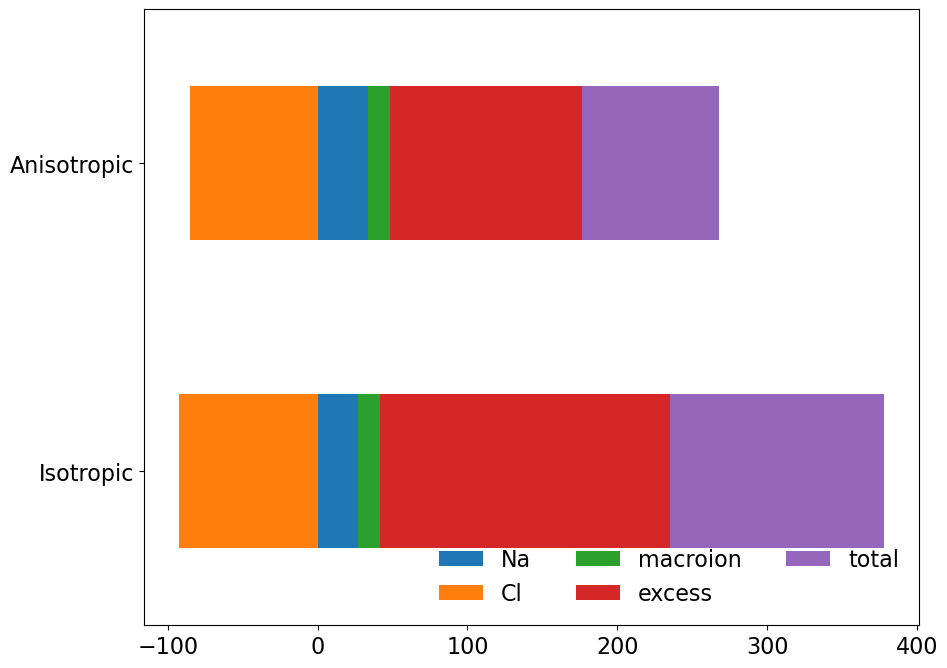

In [8]:
ax = d.plot.barh(stacked=True)
ax.legend(frameon=False, loc=4, ncol=3)

mean nonbonded energy = -315.5 kJ/mol


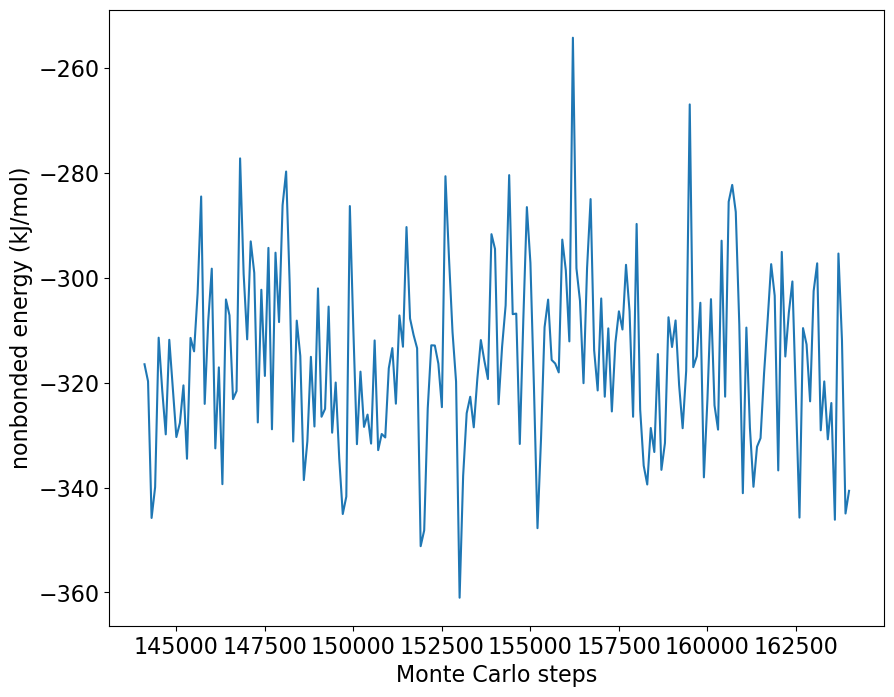

In [9]:
%cd -q $workdir/isotropic

# faunus-rs writes an energy trace as `energy.csv.gz` with columns
# step, celloverlap, nonbonded, total. The standalone `pressure.dat.gz`
# from the C++ build is gone — excess pressure is now in `output.yaml`.
energy = pd.read_csv("energy.csv.gz")
plt.plot(energy["step"], energy["nonbonded"])
plt.xlabel("Monte Carlo steps")
plt.ylabel("nonbonded energy (kJ/mol)")
print(f"mean nonbonded energy = {energy['nonbonded'].mean():.4g} kJ/mol")

Text(0.5, 0, '$r$/Å')

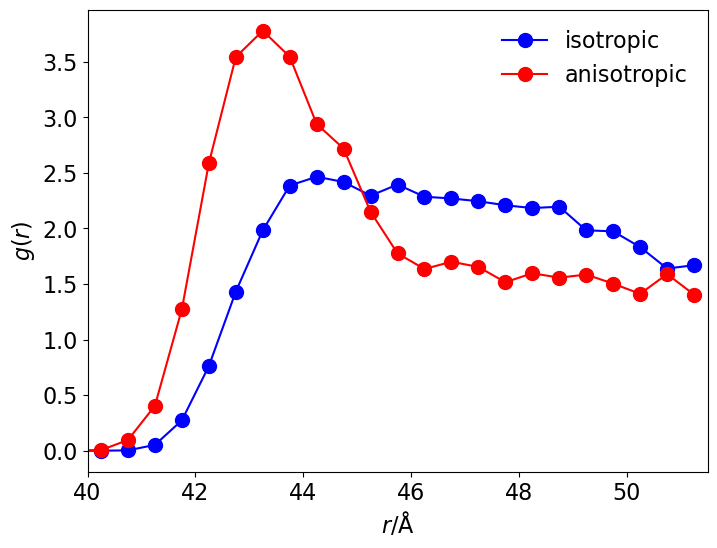

In [10]:
plt.rcParams.update({"font.size": 16, "figure.figsize": [8, 6]})

# Macroion–macroion COM RDF (now `rdf.csv` from faunus-rs).
%cd -q $workdir/isotropic
df = pd.read_csv("rdf.csv")
plt.plot(df["r"], df["g(r)"], "bo-", label="isotropic", ms=10)

%cd -q $workdir/dipolar
df = pd.read_csv("rdf.csv")
plt.plot(df["r"], df["g(r)"], "ro-", label="anisotropic", ms=10)

plt.legend(loc=0, frameon=False)
plt.xlim(40, 103 / 2)
plt.ylabel(r"$g(r)$")
plt.xlabel(r"$r$/Å")
#plt.savefig("plot.pdf", bbox_inches="tight")

Text(0.5, 0, '$r$/Å')

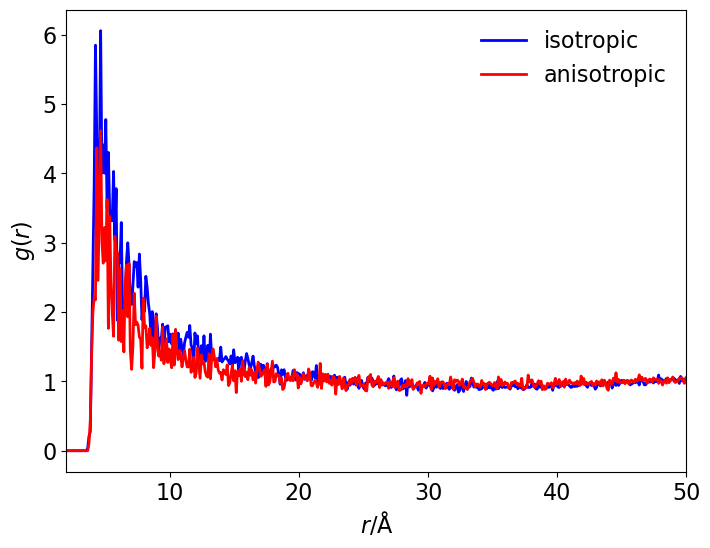

In [11]:
plt.rcParams.update({"font.size": 16, "figure.figsize": [8.0, 6]})

# Na–Cl pair RDF (now `rdf-nacl.csv` from faunus-rs).
%cd -q $workdir/isotropic
df1 = pd.read_csv("rdf-nacl.csv")
plt.plot(df1["r"], df1["g(r)"], "b-", label="isotropic", lw=2)

%cd -q $workdir/dipolar
df2 = pd.read_csv("rdf-nacl.csv")
plt.plot(df2["r"], df2["g(r)"], "r-", label="anisotropic", lw=2)

plt.legend(loc=0, frameon=False)
plt.xlim(2, 50)
plt.ylabel(r"$g(r)$")
plt.xlabel(r"$r$/Å")
#plt.savefig("plot.pdf", bbox_inches="tight")